# Phase 2 — Features & Baseline Model

Predicting financial distress in U.S. private nonprofit 4-year colleges.

This notebook builds on the Phase 1 panel (`data/processed/panel.csv`):

1. Fix/verify open data issues from Phase 1 (Form 990 year alignment, Oakwood's
   missing composite-score years, a profile of institutions that never match a score).
2. Add IPEDS F2 fields for tuition/fees revenue and gifts/contributions.
3. Build year-*t* features from information available by the end of year *t*.
4. Exploratory analysis: distressed vs. non-distressed, correlation matrix.
5. A time-based train/test split.
6. A standardized logistic regression baseline with class weights.
7. Oakwood University's predicted probability of distress, year by year.

See `NOTES.md` ("Phase 2" section) for the full log of problems hit and fixes.

In [1]:
import sys
sys.path.insert(0, "../scripts")

import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

from config import YEARS, OAKWOOD_EIN

panel = pd.read_csv("../data/processed/panel.csv", dtype={"opeid": str, "ein": str})
print(f"Phase 1 panel: {panel.shape[0]} rows, {panel['unitid'].nunique()} institutions, "
      f"years {panel['fiscal_year'].min()}-{panel['fiscal_year'].max()}")
panel.head()

Phase 1 panel: 16813 rows, 1901 institutions, years 2014-2023


,unitid,institution_name_ipeds,opeid,ein,state,SECTOR,CONTROL,ICLEVEL,hbcu,total_enrollment,total_assets,total_liabilities,total_net_assets,total_revenues,total_expenses,net_assets_end_of_year,tuition_fees_revenue,contribution_revenue,fiscal_year,composite_score,institution_name_fsa,next_year_score,distressed_next_year,f990_total_revenue,f990_total_expenses,f990_total_assets_end,f990_total_liabilities_end,f990_net_assets_end
0,100690,Amridge University,02503400,237034324,AL,2,2,1,2,625.0,13848241.0,3019785.0,10828456.0,10236876.0,8348077.0,10828456.0,6765224.0,3411947.0,2014,3.0,Amridge University,3.0,0.0,10631300.0,8742501.0,13848241.0,3019785.0,10828456.0
1,100937,Birmingham Southern College,00101200,630708730,AL,2,2,1,2,1185.0,195685360.0,72417000.0,123268360.0,48876673.0,45134655.0,123268360.0,13489284.0,13062944.0,2014,2.9,Birmingham-Southern College,2.0,0.0,NaN,NaN,NaN,NaN,NaN
2,101073,Concordia College Alabama,01055400,630389941,AL,2,2,1,1,546.0,17760303.0,3817334.0,13942969.0,12860451.0,13032162.0,13942969.0,2843422.0,3129926.0,2014,2.6,Concordia College Alabama,NaN,NaN,13977422.0,14290697.0,17760303.0,3817334.0,13942969.0
3,101189,Faulkner University,00100300,630329409,AL,2,2,1,2,3335.0,89110757.0,42162603.0,46948154.0,42846547.0,44565242.0,46948154.0,33781384.0,2373720.0,2014,2.2,Faulkner University,2.7,0.0,52612603.0,54918760.0,88544132.0,41927644.0,46616488.0
4,101435,Huntingdon College,00101900,630288841,AL,2,2,1,2,1160.0,81389270.0,27527679.0,53861591.0,22582643.0,20052724.0,53861591.0,10181662.0,3306395.0,2014,2.0,Huntingdon College,2.9,0.0,29957155.0,30039542.0,81389270.0,27527679.0,53861591.0


## Step 1a — Form 990 fiscal-year alignment

Phase 1 matched a Form 990 filing to a panel row when the filing's `tax_prd_yr`
equals the panel's `fiscal_year`. The open question: does ProPublica's
`tax_prd_yr` label a fiscal year by the year it *starts* or the year it *ends*?
If it's start-year, every Form 990 field in the panel is silently off by one year.

Checked two ways: (1) Oakwood's own raw filings, where `tax_prd` (`YYYYMM`) is
unambiguous, and (2) a panel-wide test of whether the *current* match (shift=0)
lines up with IPEDS `total_assets` better than shifting the Form 990 side by
±1 year.

In [2]:
from fetch_form990 import get_organization

oak_990 = get_organization(OAKWOOD_EIN)
oak_filings = pd.DataFrame(oak_990["filings_with_data"])[["tax_prd", "tax_prd_yr", "totassetsend"]]
oak_filings["tax_prd_end_year"] = (oak_filings["tax_prd"] // 100)
oak_filings["matches_ending_year"] = oak_filings["tax_prd_yr"] == oak_filings["tax_prd_end_year"]
oak_filings.sort_values("tax_prd_yr")

,tax_prd,tax_prd_yr,totassetsend,tax_prd_end_year,matches_ending_year
12,201106,2011,71057268,2011,True
11,201206,2012,75005830,2012,True
10,201306,2013,79743761,2013,True
9,201406,2014,90161674,2014,True
8,201506,2015,93725737,2015,True
7,201606,2016,93924759,2016,True
6,201706,2017,97726924,2017,True
5,201806,2018,99736770,2018,True
4,201906,2019,101474881,2019,True
3,202006,2020,104408271,2020,True


In [3]:
assert oak_filings["matches_ending_year"].all(), "tax_prd_yr does not equal tax_prd's own ending year"
print("tax_prd_yr always equals the calendar year tax_prd (YYYYMM) ENDS in, for every Oakwood filing.")
print("E.g. tax_prd=201406 (fiscal year ending June 2014) -> tax_prd_yr=2014, not 2013.")
print("So tax_prd_yr is already an ENDING-year label, matching how panel fiscal_year is defined.")

tax_prd_yr always equals the calendar year tax_prd (YYYYMM) ENDS in, for every Oakwood filing.
E.g. tax_prd=201406 (fiscal year ending June 2014) -> tax_prd_yr=2014, not 2013.
So tax_prd_yr is already an ENDING-year label, matching how panel fiscal_year is defined.


In [4]:
# Panel-wide confirmation: does the CURRENT match (tax_prd_yr == fiscal_year) line up with
# IPEDS total_assets better than shifting the Form 990 side by -1 or +1 year?
p = panel[["unitid", "fiscal_year", "total_assets"]].drop_duplicates(["unitid", "fiscal_year"])
f990 = panel[["unitid", "fiscal_year", "f990_total_assets_end"]].dropna(subset=["f990_total_assets_end"])
f990 = f990.drop_duplicates(["unitid", "fiscal_year"])

rows = []
for shift in (-1, 0, 1):
    shifted = f990.copy()
    shifted["fiscal_year_shifted"] = shifted["fiscal_year"] + shift
    m = shifted.merge(p, left_on=["unitid", "fiscal_year_shifted"], right_on=["unitid", "fiscal_year"],
                       suffixes=("_f990", "_ipeds"))
    ratio = m["f990_total_assets_end"] / m["total_assets"]
    rows.append({
        "shift_years": shift,
        "n_matched": len(m),
        "pct_within_5pct": ((ratio > 0.95) & (ratio < 1.05)).mean(),
        "median_ratio_f990_over_ipeds": ratio.median(),
    })
shift_check = pd.DataFrame(rows).set_index("shift_years")
shift_check

,n_matched,pct_within_5pct,median_ratio_f990_over_ipeds
shift_years,,,
-1,12494,0.454858,1.018334
0,14050,0.793452,1.000000
1,12553,0.460288,0.980272


In [5]:
assert shift_check.loc[0, "pct_within_5pct"] == shift_check["pct_within_5pct"].max(), \
    "A shifted year lines up better than the current (shift=0) match -- alignment IS off by one"
print("CONCLUSION: shift=0 (the current match) agrees with IPEDS total_assets within 5% for "
      f"{shift_check.loc[0, 'pct_within_5pct']:.1%} of rows, far above shift=-1 "
      f"({shift_check.loc[-1, 'pct_within_5pct']:.1%}) or shift=+1 ({shift_check.loc[1, 'pct_within_5pct']:.1%}). "
      "The existing Form 990 <-> panel fiscal_year match is correct; no year-alignment fix needed.")

CONCLUSION: shift=0 (the current match) agrees with IPEDS total_assets within 5% for 79.3% of rows, far above shift=-1 (45.5%) or shift=+1 (46.0%). The existing Form 990 <-> panel fiscal_year match is correct; no year-alignment fix needed.


## Step 1b — Oakwood's missing composite-score years

NOTES.md (Phase 1) said Oakwood has no composite score for fiscal years ending
2018 and 2022. Re-checking the panel directly first, then the raw `.xls` files
for whichever years are actually missing.

In [6]:
oak_panel = panel[panel["ein"] == OAKWOOD_EIN].sort_values("fiscal_year")
oak_panel[["fiscal_year", "opeid", "institution_name_ipeds", "composite_score", "institution_name_fsa"]]

,fiscal_year,opeid,institution_name_ipeds,composite_score,institution_name_fsa
9,2014,00103300,Oakwood University,3.0,Oakwood University
1704,2015,00103300,Oakwood University,3.0,Oakwood University
3421,2016,00103300,Oakwood University,2.8,Oakwood University
5127,2017,00103300,Oakwood University,3.0,Oakwood University
6828,2018,00103300,Oakwood University,2.7,Oakwood University
8514,2019,00103300,Oakwood University,NaN,NaN
10199,2020,00103300,Oakwood University,2.5,Oakwood University
11872,2021,00103300,Oakwood University,3.0,Oakwood University
13526,2022,00103300,Oakwood University,2.2,Oakwood University
15182,2023,00103300,Oakwood University,NaN,NaN


In [7]:
missing_years = oak_panel.loc[oak_panel["composite_score"].isna(), "fiscal_year"].tolist()
print(f"Oakwood actually has no composite_score for fiscal year(s): {missing_years}")
print("(Phase 1's NOTES.md said 2018 and 2022 -- those years DO have a score, 2.7 and 2.2; "
      "the real gap is 2019 and 2023. Logged as a NOTES.md correction below.)")

Oakwood actually has no composite_score for fiscal year(s): [2019, 2023]
(Phase 1's NOTES.md said 2018 and 2022 -- those years DO have a score, 2.7 and 2.2; the real gap is 2019 and 2023. Logged as a NOTES.md correction below.)


In [8]:
import pandas as pd

OAKWOOD_OPEID = oak_panel["opeid"].iloc[0]
for year in missing_years:
    raw = pd.read_excel(f"../data/raw/composite_scores/composite_scores_{year}.xls", header=None)
    opeid_col = raw[1].astype(str)
    hit = raw[opeid_col == OAKWOOD_OPEID]
    print(f"FY{year} raw file: OPEID {OAKWOOD_OPEID} present = {len(hit) > 0} "
          f"({len(raw)} total rows in file)")

FY2019 raw file: OPEID 00103300 present = False (3409 total rows in file)
FY2023 raw file: OPEID 00103300 present = False (2873 total rows in file)


Oakwood's OPEID does not appear anywhere in the raw FY2019 or FY2023 `.xls`
files at all (confirmed by OPEID match, not just name match — a plain text
search for "Oakwood" in those files hits an unrelated institution, "Appalachian
College of Pharmacy," located in the town of Oakwood, VA). This is a genuine
gap in the FSA source data for those two years, not a parsing bug in
`fetch_composite_scores.py`.

## Step 1c — Profile of IPEDS institutions that never match a composite score

Of 1,901 private-nonprofit-4yr institutions in the panel, how many never get a
composite score in *any* year, and what do they look like (size, state)?

In [9]:
by_inst = panel.groupby("unitid").agg(
    institution_name=("institution_name_ipeds", "first"),
    opeid=("opeid", "first"),
    state=("state", "first"),
    n_years=("fiscal_year", "count"),
    n_with_score=("composite_score", "count"),
    mean_enrollment=("total_enrollment", "mean"),
    mean_total_assets=("total_assets", "mean"),
).reset_index()

never = by_inst[by_inst["n_with_score"] == 0]
matched = by_inst[by_inst["n_with_score"] > 0]
print(f"Institutions that NEVER match a composite score: {len(never)} / {len(by_inst)} "
      f"({len(never) / len(by_inst):.1%})")

pd.DataFrame({
    "never_matched": [never["mean_enrollment"].median(), never["mean_total_assets"].median()],
    "matched_at_least_once": [matched["mean_enrollment"].median(), matched["mean_total_assets"].median()],
}, index=["median_enrollment", "median_total_assets"])

Institutions that NEVER match a composite score: 230 / 1901 (12.1%)


,never_matched,matched_at_least_once
median_enrollment,293.0,1096.5
median_total_assets,9416900.0,79974416.6


In [10]:
print("Never-matched institutions by state (top 10):")
print(never["state"].value_counts().head(10))

Never-matched institutions by state (top 10):
state
CA    33
FL    29
NY    19
PR    17
MI    11
AZ     8
OH     7
TX     7
IL     6
UT     6
Name: count, dtype: int64


In [11]:
# A second driver: some OPEIDs are shared by multiple IPEDS UNITIDs (multi-campus
# corporate entities, e.g. "Trine University-Regional/Non-Traditional Campuses"),
# and the FSA composite score is reported once per OPEID -- so only ONE of the
# sibling UNITIDs can ever match, even though the OPEID itself has a score.
opeid_unitid_counts = by_inst.groupby("opeid")["unitid"].nunique()
shared_opeids = opeid_unitid_counts[opeid_unitid_counts > 1].index

never_shared = never[never["opeid"].isin(shared_opeids)]
sibling_has_score = never_shared["opeid"].apply(
    lambda o: (by_inst.loc[by_inst["opeid"] == o, "n_with_score"] > 0).any()
)
print(f"Never-matched institutions sharing an OPEID with a sibling campus: {len(never_shared)} / {len(never)}")
print(f"  ... of those, a sibling UNITID under the same OPEID DOES get a score: {sibling_has_score.sum()}")
print("The remaining never-matched institutions are mostly small/low-enrollment colleges "
      "(median enrollment well below matched institutions) concentrated in CA, FL, NY, and "
      "Puerto Rico, that simply never appear in the FSA composite-score disclosure in this "
      "window -- a genuine coverage gap in the source, not a join bug.")

Never-matched institutions sharing an OPEID with a sibling campus: 36 / 230
  ... of those, a sibling UNITID under the same OPEID DOES get a score: 36
The remaining never-matched institutions are mostly small/low-enrollment colleges (median enrollment well below matched institutions) concentrated in CA, FL, NY, and Puerto Rico, that simply never appear in the FSA composite-score disclosure in this window -- a genuine coverage gap in the source, not a join bug.


## Step 2 — IPEDS F2 fields: tuition/fees revenue and gifts/contributions

Verified against the FY2013-14 (`F1314_F2_Dict.zip`) and FY2021-22
(`F2122_F2_Dict.zip`) data dictionaries (`varlist` + `Description` sheets) at
nces.ed.gov, and confirmed present in every year's raw F2 CSV from 2014-2023:

| Variable | Title | Used as |
|---|---|---|
| `F2D01` | "Tuition and fees - Total" (net of allowances) | `tuition_fees_revenue` |
| `F2D08` | "Private gifts, grants, and contracts - Total" | `contribution_revenue` |

`F2D08` is the standard published IPEDS "revenue by source" category; it is
slightly broader than pure gifts (it also includes private grants/contracts),
which is noted here since it affects how `contribution_share` should be read.
Both fields were added to `config.py:F2_FIELDS` and the panel was rebuilt.

In [12]:
import fetch_ipeds as fip
import fetch_composite_scores as fcs
from build_panel import build_full_panel
from quality_report import print_report

ipeds_df = fip.build_panel()
composite_df = fcs.parse_all()
panel = build_full_panel(ipeds_df, composite_df)
panel.to_csv("../data/processed/panel.csv", index=False)
print(panel[["tuition_fees_revenue", "contribution_revenue"]].describe())

       tuition_fees_revenue  contribution_revenue
count          1.602900e+04          1.602900e+04
mean           4.751755e+07          1.844712e+07
std            1.196212e+08          9.753237e+07
min            0.000000e+00         -4.316707e+06
25%            3.338284e+06          7.613330e+05
50%            1.536949e+07          2.984909e+06
75%            4.249862e+07          7.956105e+06
max            2.511047e+09          2.843444e+09


In [13]:
print_report(panel, ipeds_df, composite_df)

DATA QUALITY REPORT
Panel rows (institution-year observations): 16813
Distinct institutions (UNITID):              1901
Distinct fiscal years:                        10
Fiscal year range:                            2014-2023

--- Match rates between sources ---
IPEDS private-nonprofit-4yr rows:                     16813
  ... matched to a composite score (same opeid+year): 14607 (86.9% of panel rows)
Distinct OPEIDs in composite-score files:             4284
Distinct OPEIDs in IPEDS private-nonprofit-4yr universe: 1874
  ... overlap:                                        1658

Rows with a non-null EIN:                             16813
  ... matched to a Form 990 filing for that fiscal year: 14050 (83.6% of rows with an EIN)

--- Label balance (distressed_next_year) ---
Rows with a usable label (score observed in year t+1): 13027 (77.5% of panel)
Share distressed (score < 1.5 next year) among labeled rows: 6.7%

--- Missing values per column ---
                            missing_cou

## Step 3 — Year-*t* features

Built from information available by the end of year *t* only (each feature
uses that same fiscal year's filings, or an earlier year's enrollment for the
change features -- never a future year). IPEDS is the primary source for every
financial figure; Form 990 fills a value only where IPEDS is missing for that
institution-year (`features.py:add_combined_financials`).

| Feature | Definition |
|---|---|
| `operating_margin` | (total revenues − total expenses) / total revenues |
| `leverage` | total liabilities / total assets |
| `tuition_dependence` | tuition & fees revenue / total revenues |
| `contribution_share` | gifts/grants/contracts revenue / total revenues |
| `enrollment_change_1yr` | (enrollment_t − enrollment_t-1) / enrollment_t-1 |
| `enrollment_change_3yr` | (enrollment_t − enrollment_t-3) / enrollment_t-3 |
| `log_total_revenue` | ln(total revenues) |

`tuition_dependence` and `contribution_share` have no Form 990 fallback (990
does not break revenue into those categories), so they stay missing wherever
IPEDS F2 is missing.

In [14]:
from features import build_features, FEATURE_COLS, missingness_report

feat = build_features(panel)
print("Missingness per feature (full panel, before any imputation):")
missingness_report(feat, FEATURE_COLS)

Missingness per feature (full panel, before any imputation):


,missing_count,missing_pct
feature,,
operating_margin,293,1.7
leverage,295,1.8
tuition_dependence,874,5.2
contribution_share,874,5.2
enrollment_change_1yr,2219,13.2
enrollment_change_3yr,5787,34.4
log_total_revenue,330,2.0


In [15]:
feat[FEATURE_COLS].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
operating_margin,16520.0,0.028630,1.492083,-49.832518,-0.033337,0.048550,0.147383,143.479545
leverage,16518.0,0.345558,1.128383,0.000000,0.156125,0.270720,0.413718,74.420778
tuition_dependence,15939.0,0.514627,0.307734,-2.572508,0.333129,0.529223,0.694444,13.387928
contribution_share,15939.0,0.162408,0.342621,-20.126234,0.040372,0.101370,0.214211,19.989922
enrollment_change_1yr,14594.0,0.002963,0.234733,-0.983957,-0.060580,-0.007510,0.040371,15.000000
enrollment_change_3yr,11026.0,0.028893,0.956739,-0.978947,-0.135698,-0.024339,0.080185,76.500000
log_total_revenue,16483.0,17.210315,1.770958,6.086775,16.060433,17.333475,18.274983,23.637740


## Step 4 — Exploratory analysis

Distressed vs. non-distressed feature comparison (labeled rows only) and a
feature correlation matrix. Charts saved to `reports/figures/`.

In [16]:
from eda import feature_comparison_table

comparison = feature_comparison_table(feat, FEATURE_COLS)
comparison

,median_not_distressed,median_distressed,mannwhitney_p
feature,,,
operating_margin,0.059152,-0.012458,1.342655e-71
leverage,0.258445,0.463897,7.424265e-117
tuition_dependence,0.535362,0.508542,5.083004e-02
contribution_share,0.101740,0.143188,7.876818e-12
enrollment_change_1yr,-0.007395,-0.028795,6.235460e-07
enrollment_change_3yr,-0.020207,-0.084675,1.777039e-10
log_total_revenue,17.472632,16.401129,2.718361e-107


In [17]:
from pathlib import Path
from eda import plot_feature_distributions, plot_correlation_matrix

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plot_feature_distributions(feat, FEATURE_COLS, FIG_DIR / "feature_distributions.png")
plot_correlation_matrix(feat, FEATURE_COLS, FIG_DIR / "correlation_matrix.png")
print(f"Saved {FIG_DIR / 'feature_distributions.png'} and {FIG_DIR / 'correlation_matrix.png'}")

Saved ..\reports\figures\feature_distributions.png and ..\reports\figures\correlation_matrix.png


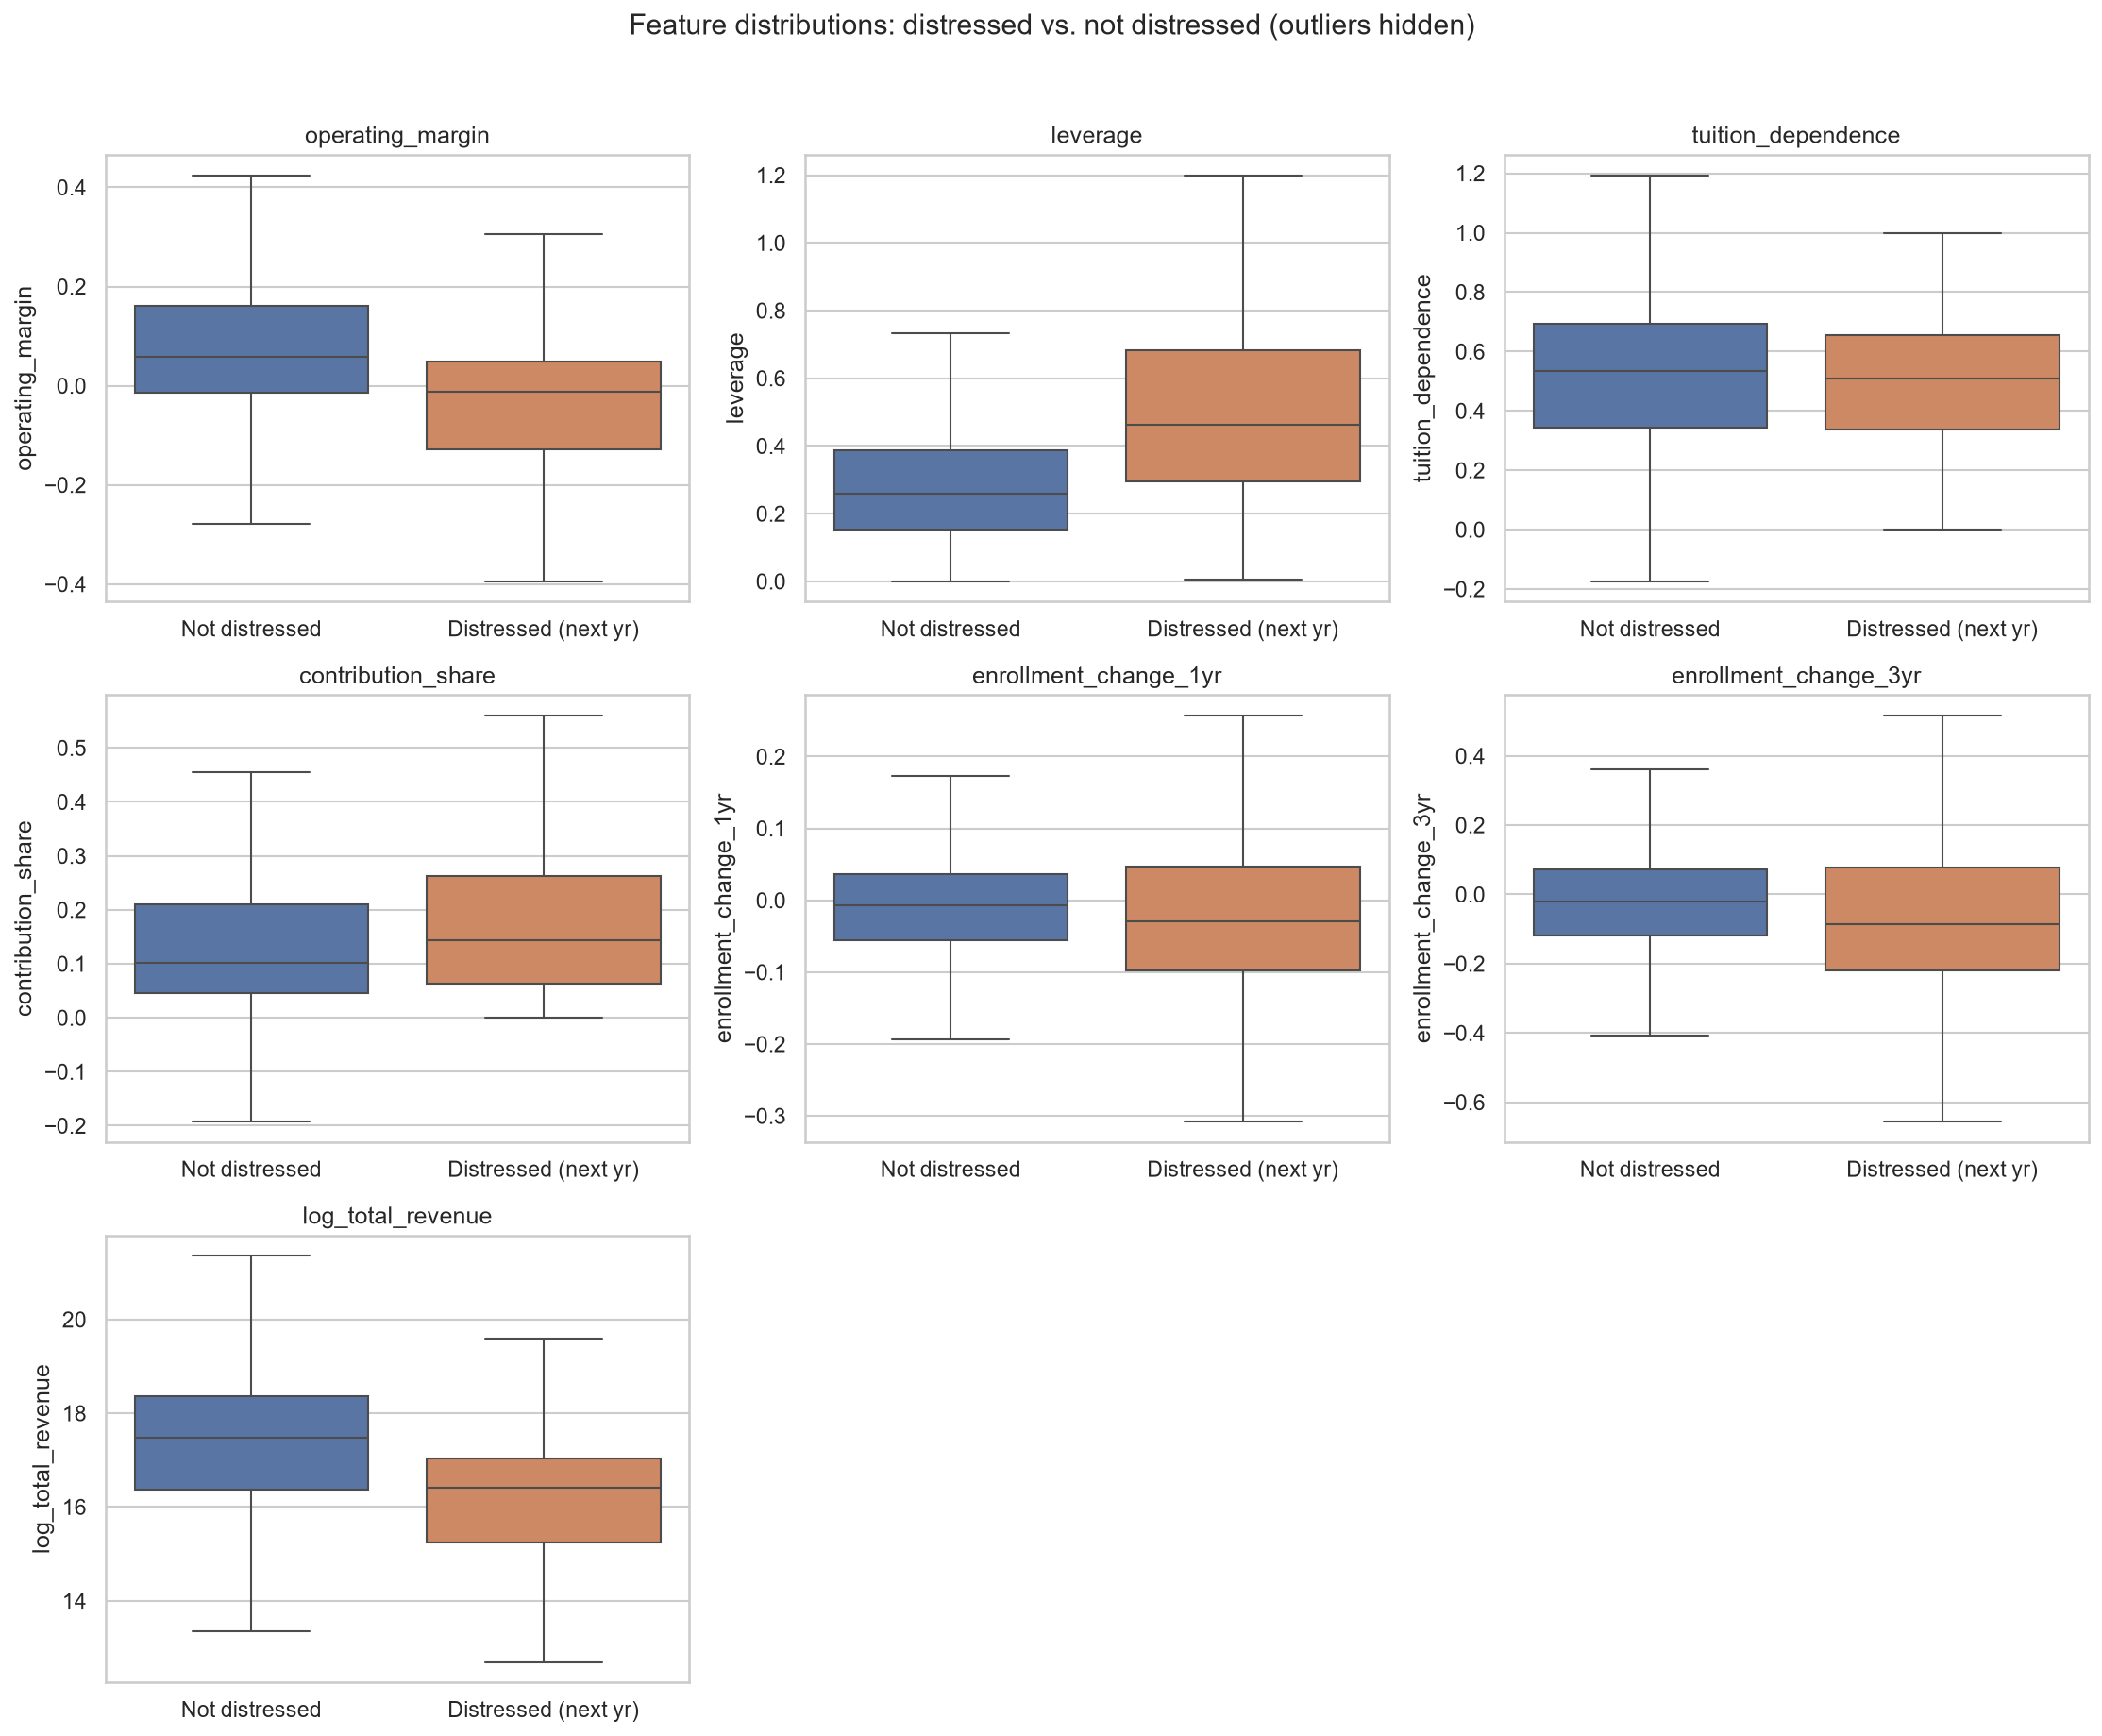

In [18]:
from IPython.display import Image, display

display(Image(filename=str(FIG_DIR / "feature_distributions.png")))

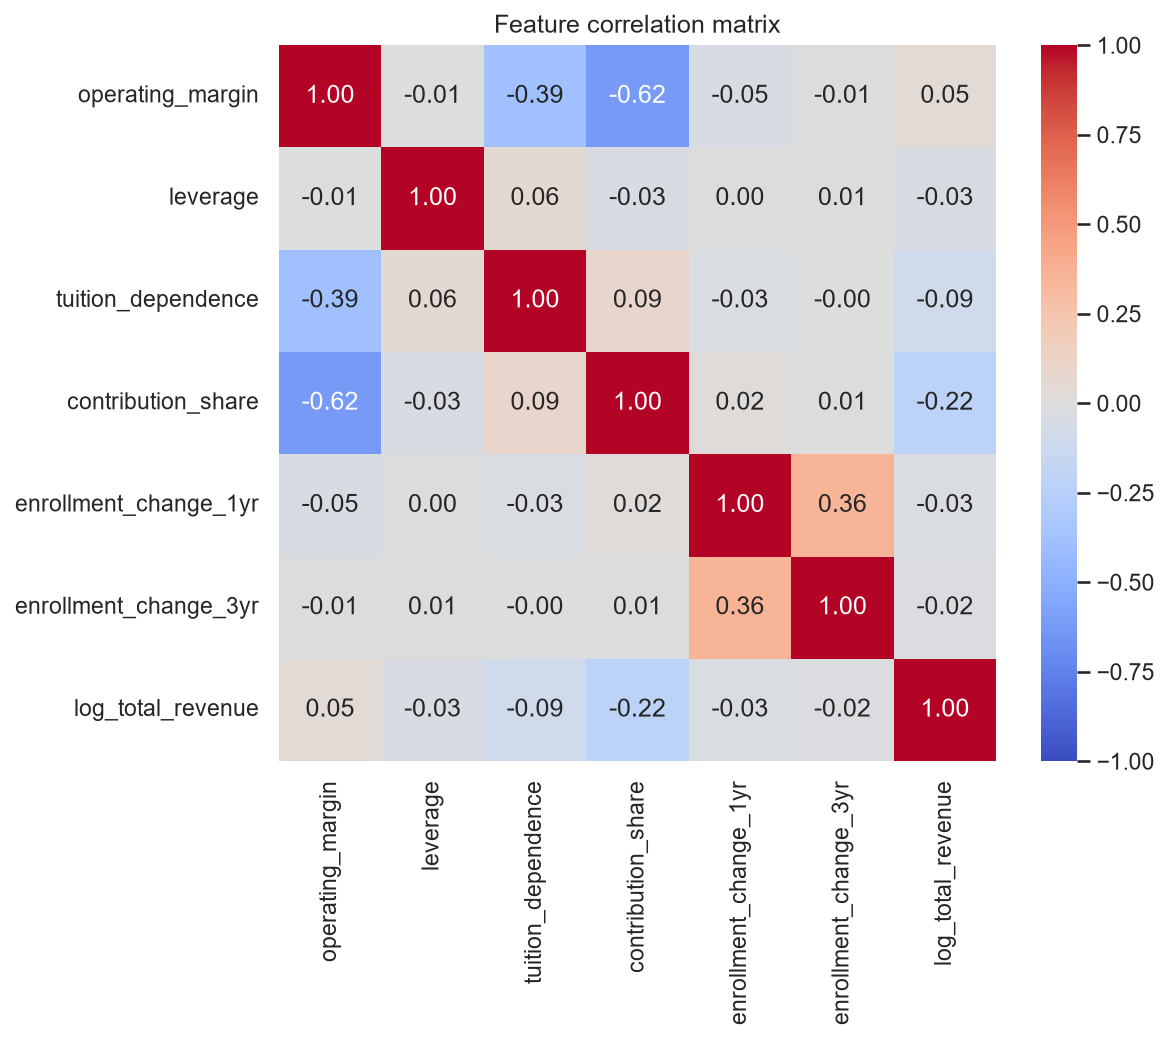

In [19]:
display(Image(filename=str(FIG_DIR / "correlation_matrix.png")))

## Step 5 — Time-based train/test split

Labeled rows (a usable `distressed_next_year`) span fiscal years 2014-2022
(2023 has no label since there's no 2024 composite-score file yet to look up).
**Train on 2014-2019, test on 2020-2022** — the model only ever sees years
strictly before anything it is evaluated on, which is the right way to
validate a model meant to predict forward in time (a random row-level split
would let the model "see the future" via same-year correlated institutions).
The test window also includes FY2020, the first full pandemic-disrupted fiscal
year for most of these institutions — a meaningful real-world stress test for
a baseline model.

In [20]:
from model import time_based_split

labeled = feat[feat["distressed_next_year"].notna()].copy()
TRAIN_YEARS = range(2014, 2020)
TEST_YEARS = range(2020, 2023)

train_df, test_df = time_based_split(labeled, TRAIN_YEARS, TEST_YEARS)
print(f"Train: {len(train_df)} rows, fiscal years {sorted(train_df.fiscal_year.unique())}, "
      f"{train_df['distressed_next_year'].mean():.1%} distressed")
print(f"Test:  {len(test_df)} rows, fiscal years {sorted(test_df.fiscal_year.unique())}, "
      f"{test_df['distressed_next_year'].mean():.1%} distressed")

Train: 8981 rows, fiscal years [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)], 7.3% distressed
Test:  4046 rows, fiscal years [np.int64(2020), np.int64(2021), np.int64(2022)], 5.3% distressed


## Step 6 — Baseline: standardized logistic regression

Preprocessing is fit on the **training rows only** and then applied to both
train and test, in this order:

1. **Winsorize** each feature at the training set's 1st/99th percentile (a few
   ratio features have multi-hundred-percent outliers from institutions with a
   near-zero denominator in a given year — e.g. enrollment of 3 dropping to 1 —
   which would otherwise dominate a standardized linear model).
2. **Median-impute** remaining missing values using the (winsorized) training
   median per feature.
3. **Standardize** (zero mean, unit variance) using the training mean/std.
4. Fit `LogisticRegression(class_weight="balanced")` to offset the ~5-7%
   distressed base rate.

In [21]:
from features import fit_clip_bounds, apply_clip, fit_median_imputer, apply_imputer
from model import fit_baseline, evaluate, naive_baseline, coefficients_table

clip_bounds = fit_clip_bounds(train_df, FEATURE_COLS)
train_clipped = apply_clip(train_df, clip_bounds, FEATURE_COLS)
test_clipped = apply_clip(test_df, clip_bounds, FEATURE_COLS)

impute_values = fit_median_imputer(train_clipped, FEATURE_COLS)
train_ready = apply_imputer(train_clipped, impute_values, FEATURE_COLS)
test_ready = apply_imputer(test_clipped, impute_values, FEATURE_COLS)

clf, scaler = fit_baseline(train_ready, FEATURE_COLS)
metrics = evaluate(clf, scaler, test_ready, FEATURE_COLS)
naive = naive_baseline(test_ready)

print("Logistic regression (test set):")
for k in ("n_test", "base_rate", "roc_auc", "pr_auc", "precision", "recall"):
    print(f"  {k}: {metrics[k]:.4f}" if isinstance(metrics[k], float) else f"  {k}: {metrics[k]}")
print("  confusion_matrix [[TN, FP], [FN, TP]]:")
print(" ", metrics["confusion_matrix"])

print("\nNaive baseline (always predict not distressed):")
print(f"  accuracy: {naive['accuracy']:.4f}  (equals 1 - test base rate)")
print(f"  precision/recall on distressed class: {naive['precision']:.4f} / {naive['recall']:.4f} "
      "(0 by construction -- it never predicts positive)")

Logistic regression (test set):
  n_test: 4046
  base_rate: 0.0529
  roc_auc: 0.8483
  pr_auc: 0.2977
  precision: 0.1732
  recall: 0.7056
  confusion_matrix [[TN, FP], [FN, TP]]:
  [[3111  721]
 [  63  151]]

Naive baseline (always predict not distressed):
  accuracy: 0.9471  (equals 1 - test base rate)
  precision/recall on distressed class: 0.0000 / 0.0000 (0 by construction -- it never predicts positive)


In [22]:
coef_table = coefficients_table(clf, FEATURE_COLS)
coef_table

,feature,coefficient
6,log_total_revenue,-1.130344
1,leverage,0.991330
2,tuition_dependence,-0.480091
0,operating_margin,-0.369195
3,contribution_share,-0.084659
4,enrollment_change_1yr,-0.078384
5,enrollment_change_3yr,-0.061494


## Step 7 — Oakwood University: predicted probability of distress by year

Applying the fitted baseline (train-set clip bounds, imputer, and scaler) to
every one of Oakwood's panel rows, including years outside the labeled
train/test window.

In [23]:
oak_feat = feat[feat["ein"] == OAKWOOD_EIN].sort_values("fiscal_year").copy()
oak_ready = apply_imputer(apply_clip(oak_feat, clip_bounds, FEATURE_COLS), impute_values, FEATURE_COLS)
oak_X = scaler.transform(oak_ready[FEATURE_COLS])
oak_feat["predicted_prob_distress"] = clf.predict_proba(oak_X)[:, 1]

oak_feat["split"] = oak_feat["fiscal_year"].apply(
    lambda y: "train" if y in TRAIN_YEARS else ("test" if y in TEST_YEARS else "unlabeled")
)
oakwood_result = oak_feat[["fiscal_year", "split", "composite_score", "next_year_score",
                            "distressed_next_year", "predicted_prob_distress"]]
oakwood_result

,fiscal_year,split,composite_score,next_year_score,distressed_next_year,predicted_prob_distress
90,2014,train,3.0,3.0,0.0,0.210597
91,2015,train,3.0,2.8,0.0,0.182802
92,2016,train,2.8,3.0,0.0,0.185293
93,2017,train,3.0,2.7,0.0,0.175930
94,2018,train,2.7,NaN,NaN,0.174571
95,2019,train,NaN,2.5,0.0,0.173944
96,2020,test,2.5,3.0,0.0,0.208099
97,2021,test,3.0,2.2,0.0,0.168201
98,2022,test,2.2,NaN,NaN,0.466454
99,2023,unlabeled,NaN,NaN,NaN,0.489710


Oakwood's actual composite score never dropped below 1.5, so every observed
`distressed_next_year` label is 0 — and the model's predicted probability
stays well under 0.5 for FY2014-2021. It rises noticeably in FY2022-2023
(to ~0.47-0.49), consistent with Oakwood's composite score trending down over
the period (3.0 -> 2.2) even though it stayed above the distress threshold.

## Save results summary

Writes `reports/phase2_results.txt` with the headline numbers from every step above.

In [24]:
summary_lines = []


def line(s=""):
    summary_lines.append(s)


line("=" * 70)
line("PHASE 2 RESULTS SUMMARY")
line("=" * 70)

line("\n--- Step 1: data issue fixes ---")
line("1a. Form 990 fiscal-year alignment: CONFIRMED CORRECT, no fix needed.")
line("    tax_prd_yr labels a filing by the calendar year its tax_prd (YYYYMM) ENDS in")
line("    (e.g. tax_prd=201406 -> tax_prd_yr=2014), matching how panel fiscal_year is")
line("    defined. Panel-wide check: the current match (shift=0) agrees with IPEDS")
line(f"    total_assets within 5% for {shift_check.loc[0, 'pct_within_5pct']:.1%} of rows, vs. "
     f"{shift_check.loc[-1, 'pct_within_5pct']:.1%} (shift=-1) and "
     f"{shift_check.loc[1, 'pct_within_5pct']:.1%} (shift=+1).")
line(f"1b. Oakwood's actual missing composite-score years: {missing_years} "
     "(NOT 2018/2022 as Phase 1's NOTES.md said -- that was a transcription error,")
line("    corrected below). Confirmed Oakwood's OPEID is genuinely absent from the raw")
line("    FY2019 and FY2023 FSA .xls files -- a source data gap, not a pipeline bug.")
line(f"1c. {len(never)}/{len(by_inst)} ({len(never) / len(by_inst):.1%}) of IPEDS private-nonprofit-4yr")
line("    institutions never match a composite score in any year. They are smaller than")
line(f"    matched institutions (median enrollment {never['mean_enrollment'].median():.0f} vs. "
     f"{matched['mean_enrollment'].median():.0f}), concentrated in CA/FL/NY/PR, and "
     f"{len(never_shared)} of them")
line("    share an OPEID with a sibling branch campus that DOES get a score (the FSA score")
line("    applies at the OPEID/corporate-entity level, not per IPEDS UNITID branch campus).")

line("\n--- Step 2: new IPEDS F2 fields ---")
line("Added F2D01 (tuition_fees_revenue) and F2D08 (contribution_revenue), verified against")
line("the FY2013-14 and FY2021-22 F2 data dictionaries and present in every year 2014-2023.")

line("\n--- Step 3: features & missingness ---")
miss = missingness_report(feat, FEATURE_COLS)
for feature, row in miss.iterrows():
    line(f"  {feature:24s} missing {int(row['missing_count']):5d} rows ({row['missing_pct']}%)")
line("Missing rule: IPEDS primary, Form 990 fallback for revenue/expenses/assets/liabilities")
line("(no fallback available for tuition_dependence/contribution_share). Remaining missing")
line("values are winsorized (train 1st/99th pct) then median-imputed using TRAINING DATA ONLY.")

line("\n--- Step 5: time-based split ---")
line(f"Train: fiscal years {TRAIN_YEARS.start}-{TRAIN_YEARS.stop - 1} ({len(train_df)} rows, "
     f"{train_df['distressed_next_year'].mean():.1%} distressed)")
line(f"Test:  fiscal years {TEST_YEARS.start}-{TEST_YEARS.stop - 1} ({len(test_df)} rows, "
     f"{test_df['distressed_next_year'].mean():.1%} distressed)")

line("\n--- Step 6: baseline logistic regression (test set) ---")
line(f"ROC-AUC:   {metrics['roc_auc']:.3f}")
line(f"PR-AUC:    {metrics['pr_auc']:.3f}")
line(f"Precision (distressed class): {metrics['precision']:.3f}")
line(f"Recall (distressed class):    {metrics['recall']:.3f}")
line(f"Confusion matrix [[TN, FP], [FN, TP]]: {metrics['confusion_matrix'].tolist()}")
line(f"\nNaive baseline (always predict not distressed): accuracy {naive['accuracy']:.3f}, "
     "precision/recall on distressed class 0.000/0.000")
line("\nCoefficients (standardized features, sorted by |coefficient|):")
for _, r in coef_table.iterrows():
    line(f"  {r['feature']:24s} {r['coefficient']:+.3f}")

line("\n--- Step 7: Oakwood University predicted probability of distress ---")
for _, r in oakwood_result.iterrows():
    line(f"  FY{int(r['fiscal_year'])} ({r['split']:9s}): predicted_prob={r['predicted_prob_distress']:.3f}, "
         f"composite_score={r['composite_score']}, actual_label={r['distressed_next_year']}")

summary_text = "\n".join(summary_lines)
print(summary_text)

with open("../reports/phase2_results.txt", "w", encoding="utf-8") as f:
    f.write(summary_text + "\n")
print("\nSaved ../reports/phase2_results.txt")

PHASE 2 RESULTS SUMMARY

--- Step 1: data issue fixes ---
1a. Form 990 fiscal-year alignment: CONFIRMED CORRECT, no fix needed.
    tax_prd_yr labels a filing by the calendar year its tax_prd (YYYYMM) ENDS in
    (e.g. tax_prd=201406 -> tax_prd_yr=2014), matching how panel fiscal_year is
    defined. Panel-wide check: the current match (shift=0) agrees with IPEDS
    total_assets within 5% for 79.3% of rows, vs. 45.5% (shift=-1) and 46.0% (shift=+1).
1b. Oakwood's actual missing composite-score years: [2019, 2023] (NOT 2018/2022 as Phase 1's NOTES.md said -- that was a transcription error,
    corrected below). Confirmed Oakwood's OPEID is genuinely absent from the raw
    FY2019 and FY2023 FSA .xls files -- a source data gap, not a pipeline bug.
1c. 230/1901 (12.1%) of IPEDS private-nonprofit-4yr
    institutions never match a composite score in any year. They are smaller than
    matched institutions (median enrollment 293 vs. 1096), concentrated in CA/FL/NY/PR, and 36 of them
    sh